# 13 - Main specification: estimator robustness and influential observations

Two questions about the main Callaway-Sant'Anna result of notebook 12 (never-treated controls more than 35 km from any protected cell, STATUS_YR-based dating):

**A. Does the covariate-adjusted estimate depend on how the covariates enter?** R `did` with notebook 12's seven covariates (geography, baseline forest, Chen et al. nightlights and coca as running pre-means, coca missing flag) via outcome regression (`reg`, no propensity score), inverse probability weighting (`ipw`) and `DRDID::drdid_panel` with stricter trimming (`trim.level = 0.95`, passed to `att_gt` as a custom estimator, the package's documented option; at the default 0.995 it reproduces the built-in `dr` exactly). Two DR comparisons isolate the covariate choices: DMSP instead of Chen nightlights (same running pre-means), and notebook 04's **frozen** DMSP and coca (treated cells measured before their own treatment, never-treated cells over a window ending in 2013). Plus per-cohort overlap diagnostics.

**B. Which observations make the estimate weak?** R's influence function of the overall ATT gives every cell's pull on the estimate ($\psi_i$; removing cell $i$ moves the ATT by about $-\psi_i$) and its contribution to the spatial-HAC variance, $v_i = \psi_i (K\psi)_i$ with $\sum_i v_i = \widehat{\text{Var}}_{\text{HAC}}$. These are aggregated by cohort, protected area and 35 km block, mapped, and used to re-estimate the ATT without the most influential areas, without the outlying 2013 cohort, and with the outcome winsorised.

In [1]:
from pathlib import Path
import math
import shutil
import sys
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'notebooks').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from utils.fast_did_utils import outcome_matrix, cohort_att_gt, GTAccumulator, ConleyLattice
from utils.r_did_bridge import write_r_inputs, run_r, read_run, remove_run_files
from utils.covariate_windows import build_dr_covariates

INTERMEDIATE_DIR = PROJECT_ROOT / 'data' / 'intermediate'
TABLE_DIR = PROJECT_ROOT / 'outputs' / 'tables'
FIG_DIR = PROJECT_ROOT / 'outputs' / 'figures'
warnings.filterwarnings('ignore', category=FutureWarning)

RUN_TAG = '1km'
START_YEAR = 2001
CELL_COL, YEAR_COL, OUTCOME_COL = 'cell_id', 'year', 'loss_m2'
PANEL_PATH = INTERMEDIATE_DIR / f'panel_treatment_{RUN_TAG}.parquet'
COVARIATE_PATH = INTERMEDIATE_DIR / f'panel_core_covariates_{RUN_TAG}.parquet'
CENTROID_PATH = INTERMEDIATE_DIR / 'spatial_structure' / f'03_grid_centroids_{RUN_TAG}.parquet'
DATING_PATH = INTERMEDIATE_DIR / f'protected_area_dating_{RUN_TAG}.parquet'
WDPA_PATH = INTERMEDIATE_DIR / 'wdpa_colombia_yearly_snapshots.parquet'
NB12_OVERALL = TABLE_DIR / f'12_cs_overall_att_by_control_group_{RUN_TAG}.csv'
R_WORK_DIR = INTERMEDIATE_DIR / '13_r_did_work'
GEE_COVARIATE_DIR = PROJECT_ROOT / 'data' / 'raw' / 'gee_covariates_core_1km'
COCA_PANEL_PATH = INTERMEDIATE_DIR / f'panel_coca_{RUN_TAG}.parquet'
CHEN_NTL_PATH = INTERMEDIATE_DIR / f'chen_ntl_{RUN_TAG}.parquet'
R_LOG = TABLE_DIR / f'13_r_did_log_{RUN_TAG}.txt'

BUFFER_KM = 35.0
GEOGRAPHY_COVARIATES = ['elevation_m_mean', 'slope_deg_mean', 'ruggedness_m_mean', 'base_m2']
NIGHTLIGHTS_COVARIATE = 'chen_ntl_pre_mean'                    # Chen et al. harmonised nightlights, as notebook 12
COCA_COVARIATE, COCA_MISSING_FLAG = 'coca_pre_mean_ha', 'coca_data_missing'
DR_COVARIATES = GEOGRAPHY_COVARIATES + [NIGHTLIGHTS_COVARIATE, COCA_COVARIATE, COCA_MISSING_FLAG]
TRIM_LEVEL = 0.95
HAC_CUTOFF_KM, BLOCK_KM = 35.0, 35.0
EVENT_WINDOW = (-8, 5)
TOP_K_AREAS = 5                 # protected areas dropped in the leave-out re-estimate
WINSOR_Q = 0.999                # cell-year loss winsorised at this quantile

## Data (as notebook 12, main specification only)

In [2]:
t0 = time.time()
panel = pd.read_parquet(PANEL_PATH, columns=[CELL_COL, YEAR_COL, OUTCOME_COL, 'first_treat_year'])
panel[CELL_COL] = panel[CELL_COL].astype(str)
panel = panel[panel[YEAR_COL] >= START_YEAR]
cell_ids, years, Y = outcome_matrix(panel, CELL_COL, YEAR_COL, OUTCOME_COL)
g_raw = panel.drop_duplicates(CELL_COL).set_index(CELL_COL)['first_treat_year'].reindex(cell_ids).fillna(0).astype(int).to_numpy()
del panel
never, in_window = g_raw == 0, g_raw > START_YEAR
g_cell = np.where(in_window, g_raw, 0)
n_cells = len(cell_ids)
uid = np.arange(1, n_cells + 1, dtype=np.int64)

cent = pd.read_parquet(CENTROID_PATH, columns=[CELL_COL, 'centroid_x_m', 'centroid_y_m', 'centroid_lon', 'centroid_lat'])
cent[CELL_COL] = cent[CELL_COL].astype(str)
cent = cent.set_index(CELL_COL).reindex(cell_ids)
xy = cent[['centroid_x_m', 'centroid_y_m']].to_numpy(dtype=float)
lonlat = cent[['centroid_lon', 'centroid_lat']].to_numpy(dtype=float)
ctrl = never & (cKDTree(xy[~never]).query(xy, k=1)[0] / 1000.0 > BUFFER_KM)

analysis = never | in_window
dr_cov = build_dr_covariates(cell_ids, years, g_raw, covariate_path=COVARIATE_PATH, gee_dir=GEE_COVARIATE_DIR, coca_panel_path=COCA_PANEL_PATH,
                             geography=GEOGRAPHY_COVARIATES, nightlights=NIGHTLIGHTS_COVARIATE, coca=COCA_COVARIATE, coca_flag=COCA_MISSING_FLAG,
                             chen_path=CHEN_NTL_PATH)
assert dr_cov['names'] == DR_COVARIATES
covariates, covariates_by_year, x_at = dr_cov['static'], dr_cov['by_year'], dr_cov['x_at']

dating = pd.read_parquet(DATING_PATH, columns=[CELL_COL, 'c_site_id'])
dating[CELL_COL] = dating[CELL_COL].astype(str)
site_of = dating.set_index(CELL_COL)['c_site_id'].reindex(cell_ids).to_numpy()
w = pd.read_parquet(WDPA_PATH, columns=['NAME', 'WDPAID', 'SITE_ID', 'DESIG_ENG', 'wdpa_snapshot_year'])
w['site_id'] = w['WDPAID'].fillna(pd.to_numeric(w['SITE_ID'], errors='coerce'))
site_name = w.sort_values('wdpa_snapshot_year').groupby('site_id')['NAME'].last()

bx = np.floor(xy[:, 0] / (BLOCK_KM * 1000)).astype(np.int64); by = np.floor(xy[:, 1] / (BLOCK_KM * 1000)).astype(np.int64)
block = pd.factorize(bx * 100_000 + by)[0]
lattice = ConleyLattice(xy[:, 0], xy[:, 1], cutoff_km=HAC_CUTOFF_KM)
cohort_sizes = pd.Series(g_cell[in_window]).value_counts().sort_index()
CONTROL_MEAN = float(Y[ctrl].mean())
print(f'{n_cells:,} cells; treated {in_window.sum():,}; controls (> {BUFFER_KM:.0f} km) {ctrl.sum():,}; control mean {CONTROL_MEAN:,.1f}  [{time.time() - t0:.0f}s]')

def normal_p(z):
    return math.erfc(abs(z) / math.sqrt(2.0)) if np.isfinite(z) else np.nan
def stars(p):
    return '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else '.' if p < 0.1 else ''

dmsp_stable_lights_pre_mean: running mean at g-1 = notebook 04 value for 100.0% of treated cells (max diff 1.4e-14); never-treated at 2013: 100.0%
coca_pre_mean_ha: running mean at g-1 = notebook 04 value for 100.0% of treated cells (max diff 1.8e-15); never-treated at 2013: 100.0%


chen_ntl_pre_mean: Chen et al. running pre-mean from 2000; cells without data 0


1,160,018 cells; treated 103,335; controls (> 35 km) 264,952; control mean 1,306.5  [40s]


## A. Estimator robustness (R `did`)

Six runs: `reg` and `ipw` with the seven covariates, and `DRDID` trimmed at 0.95, each with anticipation 0 and 1, plus the baseline and default DR again (their influence functions are needed in part B; notebook 12 deleted its own after use). All with the exact spatial HAC.

In [3]:
R_WORK_DIR.mkdir(parents=True, exist_ok=True)
keep = in_window | ctrl
long_path, cells_path = write_r_inputs(R_WORK_DIR, uid=uid, years=years, Y=Y, g_did=g_cell, keep=keep,
                                       control_flags={'buffer_35': ctrl}, covariates=covariates, covariates_by_year=covariates_by_year)
RUNS = [
    ('baseline', 'reg', False, 0, np.nan), ('dr_geography', 'dr', True, 0, np.nan),
    ('reg_covariates', 'reg', True, 0, np.nan), ('reg_covariates_anticipation1', 'reg', True, 1, np.nan),
    ('ipw', 'ipw', True, 0, np.nan), ('ipw_anticipation1', 'ipw', True, 1, np.nan),
    ('dr_trim095', 'dr_trim', True, 0, TRIM_LEVEL), ('dr_trim095_anticipation1', 'dr_trim', True, 1, TRIM_LEVEL),
]
runs = pd.DataFrame([{'run_id': f'b35__{name}', 'control_flag': 'ctrl_buffer_35', 'control_group': 'nevertreated', 'est_method': est,
                      'use_covariates': cv, 'anticipation': an, 'control_fraction': 1.0, 'seed': 1, 'min_e': EVENT_WINDOW[0],
                      'max_e': EVENT_WINDOW[1], 'faster_mode': True, 'trim_level': tl} for name, est, cv, an, tl in RUNS])
secs = run_r(runs, R_WORK_DIR, long_path, cells_path, R_WORK_DIR / 'out', R_LOG)
print(f'R runs done in {secs / 60:.1f} min')

results, psi_store, gt_store, warn_rows = [], {}, {}, []
for (name, est, cv, an, tl), run in zip(RUNS, runs.itertuples()):
    r = read_run(R_WORK_DIR / 'out', run.run_id)
    pos = np.searchsorted(uid, r['ids'])
    simple = r['agg'].query("type == 'simple'").iloc[0]
    psi = np.zeros(n_cells); psi[pos] = r['if_simple'] / r['n']
    assert abs(np.sqrt(np.sum(psi ** 2)) - simple['se']) < 1e-6 * max(1.0, simple['se'])
    se_hac = lattice.se(psi)
    p = normal_p(simple['att'] / se_hac)
    results.append({'estimator': name, 'att': simple['att'], 'se_hac': se_hac, 'se_analytic': simple['se'], 'p': p, 'sig': stars(p),
                    'pct_of_control_mean': 100 * simple['att'] / CONTROL_MEAN})
    psi_store[name] = psi
    gt_store[name] = r['gt']
    warn_rows += [{'estimator': name, 'warning': x} for x in r['warnings'] if x != 'none']
    remove_run_files(R_WORK_DIR / 'out', run.run_id)
est_table = pd.DataFrame(results)
ref = pd.read_csv(NB12_OVERALL) if NB12_OVERALL.exists() else pd.DataFrame()
if len(ref):
    ref = ref[ref['control_group'] == 'buffer_35'][['spec', 'att', 'se_hac']].rename(columns={'spec': 'estimator', 'att': 'att_nb12', 'se_hac': 'se_hac_nb12'})
    est_table = est_table.merge(ref, on='estimator', how='left')
display(est_table.round(1))
est_table.to_csv(TABLE_DIR / f'13_estimator_robustness_buffer35_{RUN_TAG}.csv', index=False)
print('R warnings:', 'none' if not warn_rows else pd.DataFrame(warn_rows).value_counts().to_string())

R runs done in 83.8 min


,estimator,att,se_hac,se_analytic,p,sig,pct_of_control_mean,att_nb12,se_hac_nb12
0,baseline,-103.6,124.2,22.3,0.4,,-7.9,-103.6,124.2
1,dr_geography,-125.2,270.5,63.7,0.6,,-9.6,-125.2,270.5
2,reg_covariates,-270.3,329.9,43.0,0.4,,-20.7,NaN,NaN
3,reg_covariates_anticipation1,-764.7,488.4,56.1,0.1,,-58.5,NaN,NaN
4,ipw,-115.1,142.4,52.0,0.4,,-8.8,NaN,NaN
5,ipw_anticipation1,-333.3,227.3,77.0,0.1,,-25.5,NaN,NaN
6,dr_trim095,-138.8,198.2,45.8,0.5,,-10.6,NaN,NaN
7,dr_trim095_anticipation1,-426.9,321.4,53.6,0.2,,-32.7,NaN,NaN


R warnings: none


### DR with DMSP nightlights, and with notebook 04's frozen covariates

* `dr_dmsp`: DMSP (2001-2013) instead of the Chen series, same running pre-means. DMSP ends in 2013, so for every cohort from 2015 the nightlights covariate is the same 2001-2013 mean; DMSP also saturates in towns and blooms around lights.
* `dr_frozen_windows`: DMSP and coca frozen as in notebook 04: each treated cell's mean over the years before its own treatment, every never-treated cell's mean over the years up to 2013. For a cohort before 2014 its covariates then cover fewer, earlier years than its controls'.

Each with anticipation 0 and 1. `dr_dmsp` vs `dr_geography` is the effect of the nightlights source; `dr_frozen_windows` vs `dr_dmsp` the effect of measuring both groups over the same years.

In [4]:
comparisons = {
    'dr_dmsp': dict(covariates=covariates, covariates_by_year={'dmsp_stable_lights_pre_mean': dr_cov['dmsp_by_year'], COCA_COVARIATE: covariates_by_year[COCA_COVARIATE]}),
    'dr_frozen_windows': dict(covariates=dr_cov['frozen']),
}
nv_specs = []
for variant, inputs in comparisons.items():
    wd = R_WORK_DIR / variant
    lp_nv, cp_nv = write_r_inputs(wd, uid=uid, years=years, Y=Y, g_did=g_cell, keep=keep, control_flags={'buffer_35': ctrl}, **inputs)
    specs_v = [(variant, 0), (f'{variant}_anticipation1', 1)]
    nv_runs = pd.DataFrame([{'run_id': f'b35__{name}', 'control_flag': 'ctrl_buffer_35', 'control_group': 'nevertreated', 'est_method': 'dr',
                             'use_covariates': True, 'anticipation': an, 'control_fraction': 1.0, 'seed': 1, 'min_e': EVENT_WINDOW[0],
                             'max_e': EVENT_WINDOW[1], 'faster_mode': True, 'trim_level': np.nan} for name, an in specs_v])
    run_r(nv_runs, wd, lp_nv, cp_nv, wd / 'out', R_LOG)
    nv_specs += [(name, an, wd) for name, an in specs_v]
for name, an, wd in nv_specs:
    r = read_run(wd / 'out', f'b35__{name}')
    pos = np.searchsorted(uid, r['ids']); psi = np.zeros(n_cells); psi[pos] = r['if_simple'] / r['n']
    simple = r['agg'].query("type == 'simple'").iloc[0]
    se_hac = lattice.se(psi); p = normal_p(simple['att'] / se_hac)
    est_table = pd.concat([est_table, pd.DataFrame([{'estimator': name, 'att': simple['att'], 'se_hac': se_hac, 'se_analytic': simple['se'], 'p': p,
                                                      'sig': stars(p), 'pct_of_control_mean': 100 * simple['att'] / CONTROL_MEAN}])], ignore_index=True)
    psi_store[name] = psi; gt_store[name] = r['gt']
    warn_rows += [{'estimator': name, 'warning': x} for x in r['warnings'] if x != 'none']
for variant in comparisons:
    shutil.rmtree(R_WORK_DIR / variant, ignore_errors=True)
display(est_table.round(1))
est_table.to_csv(TABLE_DIR / f'13_estimator_robustness_buffer35_{RUN_TAG}.csv', index=False)

,estimator,att,se_hac,se_analytic,p,sig,pct_of_control_mean,att_nb12,se_hac_nb12
0,baseline,-103.6,124.2,22.3,0.4,,-7.9,-103.6,124.2
1,dr_geography,-125.2,270.5,63.7,0.6,,-9.6,-125.2,270.5
2,reg_covariates,-270.3,329.9,43.0,0.4,,-20.7,NaN,NaN
3,reg_covariates_anticipation1,-764.7,488.4,56.1,0.1,,-58.5,NaN,NaN
4,ipw,-115.1,142.4,52.0,0.4,,-8.8,NaN,NaN
5,ipw_anticipation1,-333.3,227.3,77.0,0.1,,-25.5,NaN,NaN
6,dr_trim095,-138.8,198.2,45.8,0.5,,-10.6,NaN,NaN
7,dr_trim095_anticipation1,-426.9,321.4,53.6,0.2,,-32.7,NaN,NaN
8,dr_dmsp,-191.1,255.1,54.1,0.5,,-14.6,NaN,NaN
9,dr_dmsp_anticipation1,-116.8,480.7,74.2,0.8,,-8.9,NaN,NaN


### Overlap diagnostics by cohort

Propensity score of cohort membership against the > 35 km controls, fitted as in `DRDID` (unpenalised logit on the seven covariates at the cohort's base year *g*-1, as R `did` uses them). With rare treatment the score is small for almost everyone, so the relevant checks are controls with a high score (they get large weights) and the effective number of controls under the IPW weights $p/(1-p)$, $\text{ESS} = (\sum w)^2/\sum w^2$.

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
rows = []
for g in sorted(int(c) for c in cohort_sizes.index):
    X, x_complete = x_at(g - 1)
    tr = (g_cell == g) & x_complete
    co = ctrl & x_complete
    rr = np.flatnonzero(tr | co)
    d = tr[rr].astype(int)
    xs = StandardScaler().fit_transform(X[rr])
    ps = LogisticRegression(penalty=None, max_iter=5000).fit(xs, d).predict_proba(xs)[:, 1]
    pc, pt = ps[d == 0], ps[d == 1]
    wt = pc / (1 - pc)
    rows.append({'cohort': g, 'n_treated': int(d.sum()), 'n_control': int((1 - d).sum()),
                 'treated_ps_median': float(np.median(pt)), 'treated_ps_p95': float(np.quantile(pt, 0.95)),
                 'controls_ps_gt_0.95': int((pc > 0.95).sum()), 'controls_ps_gt_0.995': int((pc > 0.995).sum()),
                 'control_ess': float(wt.sum() ** 2 / np.sum(wt ** 2)),
                 'top10_control_weight_share': float(np.sort(wt)[-10:].sum() / wt.sum())})
overlap = pd.DataFrame(rows)
display(overlap.round(4))
overlap.to_csv(TABLE_DIR / f'13_overlap_diagnostics_buffer35_{RUN_TAG}.csv', index=False)

,cohort,n_treated,n_control,treated_ps_median,treated_ps_p95,controls_ps_gt_0.95,controls_ps_gt_0.995,control_ess,top10_control_weight_share
0,2002,11294,264952,0.0482,0.1726,0,0,145877.4656,0.0024
1,2003,96,264952,0.3705,0.9912,0,0,36.2949,0.4052
2,2004,41,264952,0.1389,0.4368,0,0,80.1637,0.2804
3,2005,1135,264952,0.6622,0.9577,22,0,100.3623,0.2248
4,2006,780,264952,0.0147,0.5714,0,0,1192.6857,0.0554
5,2007,4207,264952,0.6625,0.9914,172,42,36.1417,0.4527
6,2008,2672,264952,0.2792,0.9218,19,0,462.5122,0.0855
7,2009,14456,264952,0.0533,0.6585,2,1,1984.8179,0.0348
8,2010,1167,264952,0.6035,0.9847,61,8,23.1181,0.5021
9,2011,12197,264952,0.4489,0.9948,235,52,10.9665,0.5165


## B. Influential observations

For the baseline and the default DR estimates: each cell's influence on the overall ATT ($\psi_i$) and its contribution to the spatial-HAC variance ($v_i = \psi_i (K\psi)_i$, summing to the HAC variance). Aggregated by cohort, protected area and 35 km block.

In [6]:
def kpsi(psi):
    from scipy.signal import fftconvolve
    G = np.zeros(lattice.shape); np.add.at(G, (lattice.iy, lattice.ix), psi)
    KG = fftconvolve(G, lattice.K, mode='same')
    return KG[lattice.iy, lattice.ix]

infl = {}
for name in ['baseline', 'dr_geography']:
    psi = psi_store[name]
    v = psi * kpsi(psi)
    infl[name] = pd.DataFrame({'cell': np.arange(n_cells), 'psi': psi, 'var_contrib': v, 'treated': in_window, 'cohort': g_cell,
                               'site_id': site_of, 'block': block})
    tot = v.sum()
    print(f"{name}: HAC variance {tot:,.0f} (SE {np.sqrt(tot):.1f}); share from treated cells {v[in_window].sum() / tot:.1%}, controls {v[~in_window].sum() / tot:.1%}")

def summarise(df, by, label):
    t = df.groupby(by).agg(cells=('cell', 'size'), att_pull=('psi', 'sum'), var_contrib=('var_contrib', 'sum'))
    t['var_share_pct'] = 100 * t['var_contrib'] / df['var_contrib'].sum()
    t = t.reindex(t['var_contrib'].abs().sort_values(ascending=False).index)
    t.insert(0, 'level', label)
    return t

for name in ['baseline', 'dr_geography']:
    df = infl[name]
    by_cohort = summarise(df[df['treated']], 'cohort', 'cohort')
    by_site = summarise(df[df['treated']], 'site_id', 'protected area')
    by_site.insert(1, 'name', by_site.index.map(lambda s: site_name.get(s, '?')))
    by_block = summarise(df, 'block', '35 km block')
    print(f"\n=== {name}: cohorts ranked by contribution to the HAC variance ===")
    display(by_cohort.head(8).round(1))
    print(f"=== {name}: protected areas ===")
    display(by_site.head(10).round(1))
    print(f"=== {name}: 35 km blocks (treated and control cells) ===")
    display(by_block.head(8).round(1))
    by_cohort.to_csv(TABLE_DIR / f'13_influence_by_cohort_{name}_{RUN_TAG}.csv')
    by_site.to_csv(TABLE_DIR / f'13_influence_by_protected_area_{name}_{RUN_TAG}.csv')
    by_block.to_csv(TABLE_DIR / f'13_influence_by_block_{name}_{RUN_TAG}.csv')

baseline: HAC variance 15,432 (SE 124.2); share from treated cells 39.5%, controls 60.5%


dr_geography: HAC variance 73,183 (SE 270.5); share from treated cells 43.6%, controls 56.4%

=== baseline: cohorts ranked by contribution to the HAC variance ===


,level,cells,att_pull,var_contrib,var_share_pct
cohort,,,,,
2011,cohort,12197,-134.9,2663.9,43.7
2018,cohort,24337,171.4,1514.9,24.8
2013,cohort,1797,21.0,865.0,14.2
2009,cohort,14456,50.6,348.5,5.7
2002,cohort,11294,-41.2,163.5,2.7
2008,cohort,2672,6.9,150.6,2.5
2007,cohort,4207,-37.3,132.5,2.2
2005,cohort,1135,-2.0,47.6,0.8


=== baseline: protected areas ===


,level,name,cells,att_pull,var_contrib,var_share_pct
site_id,,,,,,
555555853.0,protected area,Del Humedal San Silvestre,808,-49.1,1677.5,27.5
19984.0,protected area,La Serranía de Chiribiquete,15095,139.4,1362.1,22.3
555592829.0,protected area,Lago Azul los Manatìes,384,34.5,827.1,13.6
555555854.0,protected area,Serranía de los Yariguíes,4355,-41.2,510.8,8.4
555555777.0,protected area,Serranía de las Quinchas,146,-11.8,225.9,3.7
555511936.0,protected area,Yaigojé Apaporis,11118,42.8,159.8,2.6
555555855.0,protected area,Del Rio Minero y sus Zonas Aledañas,544,-8.1,146.1,2.4
303547.0,protected area,Río Puré,10343,-37.5,140.8,2.3
555555834.0,protected area,Distrito Regional de Manejo Integrado - Sitio ...,1620,12.4,99.1,1.6


...

,level,cells,att_pull,var_contrib,var_share_pct
cohort,,,,,
2018,cohort,24337,-170.4,20706.0,64.9
2009,cohort,14456,98.3,4338.3,13.6
2011,cohort,12197,-60.0,3572.8,11.2
2007,cohort,4207,-28.1,1034.3,3.2
2013,cohort,1797,28.2,894.7,2.8
2008,cohort,2672,-21.7,593.0,1.9
2002,cohort,11294,-50.8,223.0,0.7
2005,cohort,1135,7.1,127.5,0.4


=== dr_geography: protected areas ===


,level,name,cells,att_pull,var_contrib,var_share_pct
site_id,,,,,,
19984.0,protected area,La Serranía de Chiribiquete,15095,-459.3,15186.4,47.6
555555866.0,protected area,Divisoria Valle de Aburra Rio Cauca,379,66.2,2933.8,9.2
555555853.0,protected area,Del Humedal San Silvestre,808,-60.7,2253.5,7.1
555697694.0,protected area,Cerro Chimayoy,561,55.0,1347.6,4.2
555697703.0,protected area,Cinaruco,3607,76.8,1281.6,4.0
555592829.0,protected area,Lago Azul los Manatìes,384,35.0,850.0,2.7
555697753.0,protected area,Río Bravo,292,31.3,846.6,2.7
555555834.0,protected area,Distrito Regional de Manejo Integrado - Sitio ...,1620,34.2,841.2,2.6
555697689.0,protected area,Serranía de Peñas Blancas,388,-40.5,836.8,2.6


=== dr_geography: 35 km blocks (treated and control cells) ===


,level,cells,att_pull,var_contrib,var_share_pct
block,,,,,
999,35 km block,479,102.7,13515.5,18.5
1000,35 km block,1077,99.2,12663.5,17.3
850,35 km block,1271,56.3,2600.1,3.6
518,35 km block,1240,-54.1,2515.6,3.4
321,35 km block,683,-40.6,2126.8,2.9
286,35 km block,745,-52.0,1988.7,2.7
637,35 km block,1271,-45.5,1698.1,2.3
611,35 km block,1271,-42.1,1627.0,2.2


baseline: top (g,t) contributions to the overall ATT


,group,time,att,se,w,contribution
278,2013,2016,22961.98,2524.93,0.00,31.42
406,2018,2024,1531.70,96.57,0.02,28.38
404,2018,2022,1358.00,103.04,0.02,25.16
407,2018,2025,1120.70,71.60,0.02,20.77
400,2018,2018,1064.67,119.11,0.02,19.73
403,2018,2021,1033.95,100.50,0.02,19.16
405,2018,2023,1011.10,70.04,0.02,18.74
234,2011,2020,-1845.30,126.93,0.01,-17.14


dr_geography: top (g,t) contributions to the overall ATT


,group,time,att,se,w,contribution
278,2013,2016,23607.04,2563.59,0.00,32.30
404,2018,2022,868.25,273.64,0.02,16.09
227,2011,2013,-1465.16,158.03,0.01,-13.61
403,2018,2021,720.08,241.91,0.02,13.34
406,2018,2024,687.06,284.98,0.02,12.73
231,2011,2017,1307.55,348.60,0.01,12.14
401,2018,2019,598.69,235.95,0.02,11.09
234,2011,2020,-1172.49,969.51,0.01,-10.89


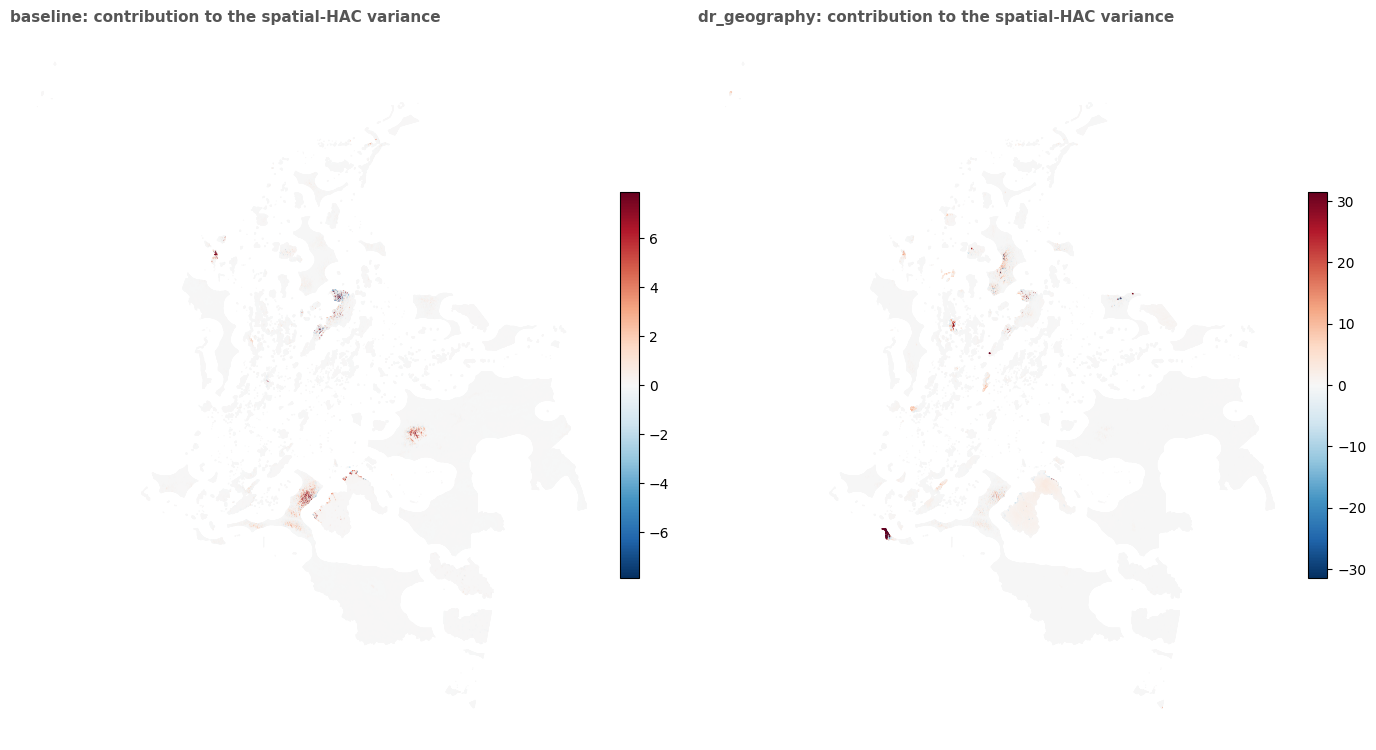

In [7]:
# Largest single (g,t) contributions to the overall ATT (weight x ATT(g,t))
for name in ['baseline', 'dr_geography']:
    gt = gt_store[name].copy()
    gt = gt[gt['time'] >= gt['group']]
    gt['w'] = gt['group'].map(cohort_sizes).astype(float)
    gt['w'] = gt['w'] / gt['w'].sum()
    gt['contribution'] = gt['w'] * gt['att']
    print(f'{name}: top (g,t) contributions to the overall ATT')
    display(gt.reindex(gt['contribution'].abs().sort_values(ascending=False).index).head(8).round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 7.5))
for ax, name in zip(axes, ['baseline', 'dr_geography']):
    df = infl[name]
    sel = np.abs(df['var_contrib'].to_numpy()) > 0
    v = df['var_contrib'].to_numpy()[sel]
    lim = np.quantile(np.abs(v), 0.999)
    sc = ax.scatter(lonlat[sel, 0], lonlat[sel, 1], c=np.clip(v, -lim, lim), cmap='RdBu_r', s=0.6, vmin=-lim, vmax=lim, linewidths=0, rasterized=True)
    ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_visible(False)
    ax.set_title(f'{name}: contribution to the spatial-HAC variance', loc='left', color='#555555', fontsize=11, weight='bold')
    fig.colorbar(sc, ax=ax, fraction=0.03, pad=0.01)
fig.tight_layout(); fig.savefig(FIG_DIR / f'13_influence_map_buffer35_{RUN_TAG}.png', dpi=220, bbox_inches='tight'); plt.show()

### Re-estimation without the influential observations

* **drop top areas**: treated cells of the `TOP_K_AREAS` protected areas with the largest contribution to the baseline HAC variance;
* **drop Lago Azul Los Manatíes** (WDPA 555592829, 384 cells of cohort 2013): one area with a one-year loss spike in 2016 (about 112,000 m² per cell, against about 1,000 in other years), which alone makes ATT(2013, 2016) about +23,000 and moves the overall ATT by about +30; only this area is dropped, not the rest of cohort 2013;
* **drop cohort 2002** (also the rule "cohorts need at least two pre-treatment years"): 21% of the overall weight, and only one pre-treatment year (2001, the first panel year), so its pre-trend cannot be checked; it is also the cohort that anticipation drops automatically (its base year *g*-2 = 2000 is outside the panel);
* **drop cohort 2002 and Lago Azul**: both issues at once (they pull the estimate in opposite directions);
* **winsorise**: cell-year loss capped at the 99.9th percentile of the analysis sample.

Baseline re-estimates use the Python estimator (identical to R for no-covariate specifications, checked in notebook 12); DR re-estimates run in R.

In [8]:
def python_baseline(Ymat, gc, label):
    acc = GTAccumulator(pd.Series(gc[gc > 0]).value_counts().sort_index().to_dict(), n_cells, anticipation=0, event_window=EVENT_WINDOW)
    for g in sorted(int(c) for c in np.unique(gc[gc > 0])):
        res, _ = cohort_att_gt(Ymat, years, gc, ctrl, g)
        acc.add(res)
    _, ov, _ = acc.result()
    se = lattice.se(ov['psi']); p = normal_p(ov['att'] / se)
    return {'variant': label, 'estimator': 'baseline', 'att': ov['att'], 'se_hac': se, 'p': p, 'sig': stars(p)}

top_sites = summarise(infl['baseline'][infl['baseline']['treated']], 'site_id', 'pa').head(TOP_K_AREAS).index.tolist()
drop_sites = np.isin(site_of, top_sites) & in_window
LAGO_AZUL_SITE = 555592829
lago_azul = (pd.to_numeric(pd.Series(site_of), errors='coerce').to_numpy(dtype=float) == LAGO_AZUL_SITE) & in_window
print(f'Lago Azul Los Manatíes: {int(lago_azul.sum())} cells (cohort {sorted(set(g_cell[lago_azul]))})')
cap = np.quantile(Y[keep], WINSOR_Q)
Yw = np.minimum(Y, cap)
variants = [
    ('full sample', g_cell, Y),
    (f'drop top {TOP_K_AREAS} areas', np.where(drop_sites, 0, g_cell), Y),
    ('drop Lago Azul Los Manatíes', np.where(lago_azul, 0, g_cell), Y),
    ('drop cohort 2002', np.where(g_cell == 2002, 0, g_cell), Y),
    ('drop cohort 2002 and Lago Azul', np.where(lago_azul | (g_cell == 2002), 0, g_cell), Y),
    (f'winsorise at p{WINSOR_Q * 100:g} ({cap:,.0f} m2)', g_cell, Yw),
]
print('Top areas dropped:', [site_name.get(s, s) for s in top_sites], f'({int(drop_sites.sum()):,} cells)')
loo = [python_baseline(Ym, gc, label) for label, gc, Ym in variants]

# DR re-estimates in R (same variants)
dr_runs, dr_labels = [], []
for k, (label, gc, Ym) in enumerate(variants[1:], start=1):
    wd = R_WORK_DIR / f'variant{k}'
    lp, cp_ = write_r_inputs(wd, uid=uid, years=years, Y=Ym, g_did=gc, keep=(gc > 0) | ctrl, control_flags={'buffer_35': ctrl}, covariates=covariates,
                             covariates_by_year=covariates_by_year)
    rid = f'variant{k}__dr'
    run_r(pd.DataFrame([{'run_id': rid, 'control_flag': 'ctrl_buffer_35', 'control_group': 'nevertreated', 'est_method': 'dr', 'use_covariates': True,
                         'anticipation': 0, 'control_fraction': 1.0, 'seed': 1, 'min_e': EVENT_WINDOW[0], 'max_e': EVENT_WINDOW[1],
                         'faster_mode': True, 'trim_level': np.nan}]), wd, lp, cp_, wd / 'out', R_LOG)
    r = read_run(wd / 'out', rid)
    pos = np.searchsorted(uid, r['ids']); psi = np.zeros(n_cells); psi[pos] = r['if_simple'] / r['n']
    att = float(r['agg'].query("type == 'simple'")['att'].iloc[0]); se = lattice.se(psi); p = normal_p(att / se)
    loo.append({'variant': label, 'estimator': 'dr_geography', 'att': att, 'se_hac': se, 'p': p, 'sig': stars(p)})
    shutil.rmtree(wd, ignore_errors=True)
full_dr = est_table.set_index('estimator').loc['dr_geography']
loo.append({'variant': 'full sample', 'estimator': 'dr_geography', 'att': full_dr['att'], 'se_hac': full_dr['se_hac'], 'p': full_dr['p'], 'sig': full_dr['sig']})
loo = pd.DataFrame(loo)
loo_table = loo.assign(cell=loo['att'].map('{:,.1f}'.format) + loo['sig'] + ' (' + loo['se_hac'].map('{:,.1f}'.format) + ')').pivot(index='variant', columns='estimator', values='cell')
display(loo_table.reindex([v[0] for v in variants]))
loo.to_csv(TABLE_DIR / f'13_leave_out_reestimates_buffer35_{RUN_TAG}.csv', index=False)
shutil.rmtree(R_WORK_DIR, ignore_errors=True)

Lago Azul Los Manatíes: 384 cells (cohort [np.int64(2013)])


Top areas dropped: ['Del Humedal San Silvestre', 'La Serranía de Chiribiquete', 'Lago Azul los Manatìes', 'Serranía de los Yariguíes', 'Serranía de las Quinchas'] (20,788 cells)


estimator,baseline,dr_geography
variant,,
full sample,-103.6 (112.6),-125.2 (270.5)
drop top 5 areas,-188.7. (104.9),-248.3 (199.5)
drop Lago Azul Los Manatíes,-138.2 (109.3),-164.4 (267.5)
drop cohort 2002,-51.7 (142.1),-64.3 (338.3)
drop cohort 2002 and Lago Azul,-95.1 (138.1),-113.4 (334.7)
"winsorise at p99.9 (136,725 m2)",-122.4 (89.8),-147.7 (212.0)


### Anticipation on the same cohorts, and what cohort 2002 is

With anticipation 1 the base year is *g*-2, so cohort 2002 (base 2000, outside the panel) drops out; comparing anticipation 0 on all cohorts with anticipation 1 mixes the anticipation assumption with that change of sample. The fair comparison is on the same cohorts (2003-2025): anticipation 0 without cohort 2002 (leave-out above) against anticipation 1 (notebook 12).

In [9]:
ref12 = pd.read_csv(NB12_OVERALL).query("control_group == 'buffer_35'").set_index('spec')
lo = loo.set_index(['variant', 'estimator'])
def fmt(att, se, sig):
    return f'{att:,.1f}{sig} ({se:,.1f})'
same_rows = []
for label, a0, a1 in [('no covariates', 'baseline', 'anticipation1'), ('DR (covariates)', 'dr_geography', 'dr_geography_anticipation1')]:
    full, no02 = lo.loc[('full sample', a0)], lo.loc[('drop cohort 2002', a0)]
    same_rows.append({'specification': label,
                      'anticipation 0, all cohorts': fmt(full['att'], full['se_hac'], full['sig']),
                      'anticipation 0, cohorts 2003-2025': fmt(no02['att'], no02['se_hac'], no02['sig']),
                      'anticipation 1, cohorts 2003-2025': fmt(ref12.loc[a1, 'att'], ref12.loc[a1, 'se_hac'], ref12.loc[a1, 'sig'] if isinstance(ref12.loc[a1, 'sig'], str) else ''),
                      'effect of anticipation (same cohorts)': round(float(ref12.loc[a1, 'att'] - no02['att']), 1),
                      'effect of cohort 2002': round(float(full['att'] - no02['att']), 1)})
same_cohorts = pd.DataFrame(same_rows)
display(same_cohorts)
same_cohorts.to_csv(TABLE_DIR / f'13_anticipation_same_cohorts_buffer35_{RUN_TAG}.csv', index=False)

# What cohort 2002 is: protected areas, designation, and cells
w2 = pd.read_parquet(WDPA_PATH, columns=['NAME', 'WDPAID', 'SITE_ID', 'DESIG_ENG', 'STATUS_YR', 'wdpa_snapshot_year'])
w2['site_id'] = w2['WDPAID'].fillna(pd.to_numeric(w2['SITE_ID'], errors='coerce'))
last = w2.sort_values('wdpa_snapshot_year').groupby('site_id').last()
c02 = pd.Series(site_of[g_cell == 2002]).value_counts().rename('cells').to_frame()
c02.index = pd.to_numeric(c02.index, errors='coerce').astype(float)
last.index = pd.to_numeric(last.index, errors='coerce').astype(float)
c02 = c02.join(last[['NAME', 'DESIG_ENG', 'STATUS_YR']], how='left')
c02['share_of_cohort_pct'] = (100 * c02['cells'] / c02['cells'].sum()).round(1)
c02['mean_annual_loss_m2'] = [float(Y[(g_cell == 2002) & (pd.to_numeric(pd.Series(site_of), errors='coerce').to_numpy(dtype=float) == sid)].mean()) for sid in c02.index]
print(f"Cohort 2002: {int((g_cell == 2002).sum()):,} cells, {100 * (g_cell == 2002).sum() / in_window.sum():.1f}% of treated cells; "
      f"weight in the overall ATT {100 * cohort_sizes.get(2002, 0) * (int(years.max()) - 2002 + 1) / sum(cohort_sizes[g] * (int(years.max()) - g + 1) for g in cohort_sizes.index):.1f}% (cohort size x post years)")
display(c02.head(8).round(1))
c02.to_csv(TABLE_DIR / f'13_cohort2002_protected_areas_{RUN_TAG}.csv')

,specification,"anticipation 0, all cohorts","anticipation 0, cohorts 2003-2025","anticipation 1, cohorts 2003-2025",effect of anticipation (same cohorts),effect of cohort 2002
0,no covariates,-103.6 (112.6),-51.7 (142.1),-337.0. (180.1),-285.3,-51.9
1,DR (covariates),-125.2 (270.5),-64.3 (338.3),-54.7 (373.9),9.6,-60.9


Cohort 2002: 11,294 cells, 10.9% of treated cells; weight in the overall ATT 20.6% (cohort size x post years)


,cells,NAME,DESIG_ENG,STATUS_YR,share_of_cohort_pct,mean_annual_loss_m2
303547.0,10190,Río Puré,National Natural Park,2002,90.2,38.7
303541.0,905,Alto Fragua - Indi Wasi,National Natural Park,2002,8.0,592.7
555592814.0,79,Los Bosques de la Chec,Regional Protective Forest Reserves,2002,0.7,137.9
303546.0,63,El Corchal El Mono Hernández,Fauna and Flora Sanctuary,2002,0.6,1835.3
555555936.0,19,Sanguare,Civil Society Nature Reserve,2002,0.2,30.4
555555734.0,15,Bremen Lote 16 y la Rinconada Lote 15,Regional Protective Forest Reserves,2002,0.1,419.3
555555727.0,12,Cerrobravo,Regional Protective Forest Reserves,2002,0.1,47.5
555555961.0,4,El Refugio De Techotiva,Civil Society Nature Reserve,2002,0.0,876.4


## C. Control-distance gradient and the HAC cutoff

### Far control bands

Notebook 12 compares the new PAs with never-treated controls in non-overlapping bands of distance to the nearest protected cell (2-10, 10-20, 20-35 km), with the main pool (> 35 km) and with all never-treated cells (no band). Two more bands beyond the main buffer, **35-50 km** and **> 50 km**, show whether the estimate settles beyond 35 km (the main pool is clean and the buffer choice does not drive the result) or keeps moving with distance (a systematic difference between landscapes near and far from PAs: regional trends or selection rather than leakage). Same four specifications as notebook 12; the other groups are read from notebook 12's results. Farther bands are smaller and geographically more distinct, so their DR estimates matter more than the baseline.

In [10]:
t0 = time.time()
dist_any_km = cKDTree(xy[~never]).query(xy, k=1)[0] / 1000.0
FAR_BANDS = {'band_35_50': ('35-50 km', 35.0, 50.0), 'band_gt50': ('> 50 km', 50.0, np.inf)}
far_masks = {k: never & (dist_any_km > lo) & (dist_any_km <= hi) for k, (_, lo, hi) in FAR_BANDS.items()}
for k, m in far_masks.items():
    print(f'{FAR_BANDS[k][0]}: {m.sum():,} never-treated control cells, mean annual loss {Y[m].mean():,.1f} m2')
SPECS_12 = [('baseline', 'reg', False, 0), ('anticipation1', 'reg', False, 1), ('dr_geography', 'dr', True, 0), ('dr_geography_anticipation1', 'dr', True, 1)]
wd = R_WORK_DIR / 'far_bands'
lp_fb, cp_fb = write_r_inputs(wd, uid=uid, years=years, Y=Y, g_did=g_cell, keep=in_window | np.logical_or.reduce(list(far_masks.values())),
                              control_flags=far_masks, covariates=covariates, covariates_by_year=covariates_by_year)
fb_runs = pd.DataFrame([{'run_id': f'{k}__{sp}', 'control_flag': f'ctrl_{k}', 'control_group': 'nevertreated', 'est_method': est,
                         'use_covariates': cv, 'anticipation': an, 'control_fraction': 1.0, 'seed': 1, 'min_e': EVENT_WINDOW[0],
                         'max_e': EVENT_WINDOW[1], 'faster_mode': True, 'trim_level': np.nan}
                        for k in far_masks for sp, est, cv, an in SPECS_12])
run_r(fb_runs, wd, lp_fb, cp_fb, wd / 'out', R_LOG)
far_rows = []
for run in fb_runs.itertuples():
    k, sp = run.run_id.split('__')
    try:
        r = read_run(wd / 'out', run.run_id)
    except RuntimeError as ex:
        print('  failed:', ex); continue
    pos = np.searchsorted(uid, r['ids']); psi = np.zeros(n_cells); psi[pos] = r['if_simple'] / r['n']
    simple = r['agg'].query("type == 'simple'").iloc[0]
    se_hac = lattice.se(psi); p = normal_p(simple['att'] / se_hac)
    cm = float(Y[far_masks[k]].mean())
    far_rows.append({'control_group': k, 'control_label': FAR_BANDS[k][0], 'spec': sp, 'engine': 'R did', 'note': '', 'att': simple['att'],
                     'se_hac': se_hac, 'se_analytic': simple['se'], 'p': p, 'sig': stars(p), 'pct_of_control_mean': 100 * simple['att'] / cm})
    warn_rows += [{'estimator': run.run_id, 'warning': x} for x in r['warnings'] if x != 'none']
    print(f"  {FAR_BANDS[k][0]:<9} {sp:<27} ATT {simple['att']:>8.1f}  SE(HAC) {se_hac:>6.1f}  SE(analytic) {simple['se']:>6.1f} {stars(p)}")
shutil.rmtree(wd, ignore_errors=True)
far = pd.DataFrame(far_rows)
far.to_csv(TABLE_DIR / f'13_far_control_bands_{RUN_TAG}.csv', index=False)
print(f'[{time.time() - t0:.0f}s]')

35-50 km: 94,805 never-treated control cells, mean annual loss 2,067.0 m2
> 50 km: 170,147 never-treated control cells, mean annual loss 882.7 m2


  35-50 km  baseline                    ATT     94.0  SE(HAC)  169.6  SE(analytic)   27.0 


  35-50 km  anticipation1               ATT    -63.9  SE(HAC)  230.9  SE(analytic)   34.9 


  35-50 km  dr_geography                ATT     18.0  SE(HAC)  249.1  SE(analytic)   53.4 


  35-50 km  dr_geography_anticipation1  ATT    173.1  SE(HAC)  323.1  SE(analytic)   54.6 


  > 50 km   baseline                    ATT   -213.8  SE(HAC)  122.0  SE(analytic)   22.6 .


  > 50 km   anticipation1               ATT   -489.2  SE(HAC)  178.4  SE(analytic)   29.9 **


  > 50 km   dr_geography                ATT   -588.1  SE(HAC)  884.8  SE(analytic)  224.9 


  > 50 km   dr_geography_anticipation1  ATT  -1074.1  SE(HAC)  832.9  SE(analytic)  184.7 
[2149s]


control_label,2-10 km,10-20 km,20-35 km,35-50 km,> 50 km,> 35 km (main),All never-treated
spec,,,,,,,
baseline,172.4* (86.0),NaN,NaN,94.0 (169.6),-213.8. (122.0),NaN,NaN
anticipation1,NaN,-258.3. (147.2),-406.6* (161.5),-63.9 (230.9),-489.2** (178.4),-337.0. (180.1),-251.6* (107.7)
dr_geography,NaN,-199.1. (114.5),NaN,18.0 (249.1),-588.1 (884.8),NaN,NaN
dr_geography_anticipation1,NaN,-294.9* (148.4),NaN,173.1 (323.1),"-1,074.1 (832.9)",NaN,NaN


Engines / notes (from notebook 12):


,control_label,spec,engine,note
16,All never-treated,baseline,python,identical to R for no-covariate specs
17,All never-treated,anticipation1,python,identical to R for no-covariate specs
18,All never-treated,dr_geography,R did,controls subsampled to 33%
19,All never-treated,dr_geography_anticipation1,R did,controls subsampled to 33%


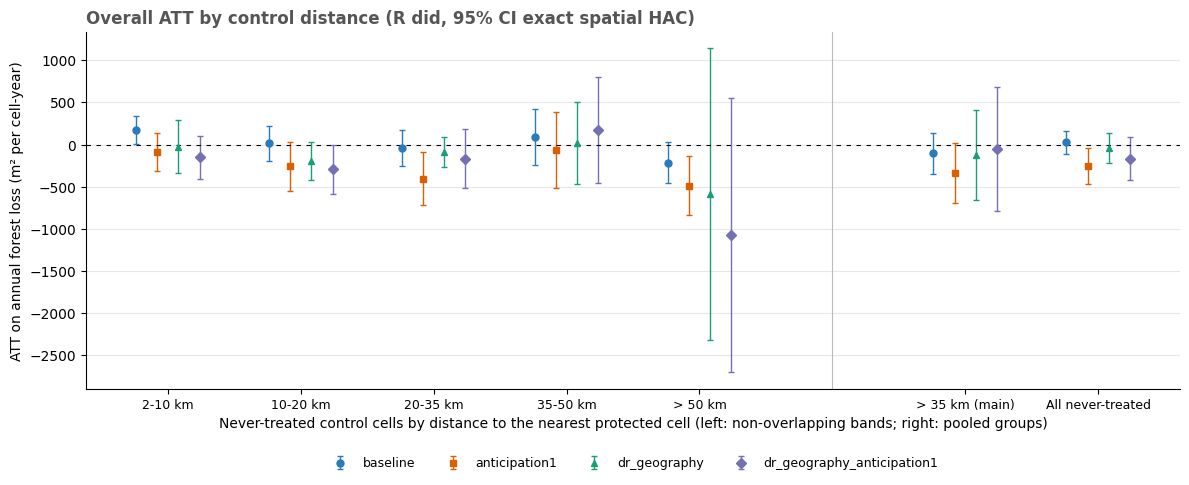

In [11]:
GRADIENT = [('band_2_10', '2-10 km'), ('band_10_20', '10-20 km'), ('band_20_35', '20-35 km'), ('band_35_50', '35-50 km'), ('band_gt50', '> 50 km'),
            ('buffer_35', '> 35 km (main)'), ('all_never', 'All never-treated')]
nb12 = pd.read_csv(NB12_OVERALL)
cols = ['control_group', 'spec', 'engine', 'note', 'att', 'se_hac', 'se_analytic', 'p', 'sig', 'pct_of_control_mean']
gradient = pd.concat([nb12[nb12['control_group'].isin([k for k, _ in GRADIENT])][cols], far[cols]], ignore_index=True)
gradient['control_label'] = gradient['control_group'].map(dict(GRADIENT))
gradient.to_csv(TABLE_DIR / f'13_control_distance_gradient_{RUN_TAG}.csv', index=False)
spec_order = [sp for sp, *_ in SPECS_12]
label_order = [lab for _, lab in GRADIENT]
cell = gradient['att'].map('{:,.1f}'.format) + gradient['sig'] + ' (' + gradient['se_hac'].map('{:,.1f}'.format) + ')'
display(gradient.assign(cell=cell).pivot(index='spec', columns='control_label', values='cell').reindex(index=spec_order, columns=label_order))
print('Engines / notes (from notebook 12):')
display(gradient[gradient['note'].fillna('') != ''][['control_label', 'spec', 'engine', 'note']])

colors = {'baseline': '#2b7bba', 'anticipation1': '#d95f02', 'dr_geography': '#1b9e77', 'dr_geography_anticipation1': '#7570b3'}
markers = {'baseline': 'o', 'anticipation1': 's', 'dr_geography': '^', 'dr_geography_anticipation1': 'D'}
xpos = {lab: i for i, lab in enumerate(label_order[:5])}
xpos[label_order[5]], xpos[label_order[6]] = 6.0, 7.0
fig, ax = plt.subplots(figsize=(12, 5))
off = np.linspace(-0.24, 0.24, len(spec_order))
for k, sp in enumerate(spec_order):
    d = gradient[gradient['spec'] == sp].set_index('control_label').reindex(label_order)
    xs = np.array([xpos[lab] for lab in label_order]) + off[k]
    ax.errorbar(xs, d['att'], yerr=1.96 * d['se_hac'], fmt=markers[sp], color=colors[sp], capsize=2.5, markersize=5, linewidth=1, label=sp)
ax.axhline(0, color='black', linewidth=0.8, linestyle=(0, (4, 5)))
ax.axvline(5.0, color='#bbbbbb', linewidth=0.8)
ax.set_xticks([xpos[lab] for lab in label_order]); ax.set_xticklabels(label_order, fontsize=9)
ax.set_xlabel('Never-treated control cells by distance to the nearest protected cell (left: non-overlapping bands; right: pooled groups)')
ax.set_ylabel('ATT on annual forest loss (m² per cell-year)')
ax.set_title('Overall ATT by control distance (R did, 95% CI exact spatial HAC)', loc='left', color='#555555', fontsize=12, weight='bold')
ax.grid(True, axis='y', color='#e7e7e7'); ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
ax.legend(frameon=False, fontsize=9, ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.16))
fig.tight_layout(); fig.savefig(FIG_DIR / f'13_control_distance_gradient_{RUN_TAG}.png', dpi=220, bbox_inches='tight'); plt.show()

### Before the post-2016 deforestation surge

After the 2016 peace agreement, forest loss surged, most of all in the frontier arc around parks in Caquetá, Guaviare and Meta (never-treated cells averaged 3,088 m² in 2017). Cells 10-20 km from a protected area lie largely in that arc, cells > 35 km away mostly do not, and the DR reweighting matches the large remote Amazon cohorts (Río Puré 2002, Yaigojé Apaporis 2009) to Amazon-like controls; with 10-20 km controls their post-2016 ATTs become strongly negative. To see how much of the estimates comes from that period, cohorts 2002-2016 are estimated (i) with all years to 2025 and (ii) with years up to 2016 only, against the > 35 km controls and the 10-20 km band. (i) vs (ii) is the effect of the post-2016 years for the same cohorts; if the two control groups agree in (ii), the band difference is the surge. Cohorts from 2017 are left out of both (in a panel ending in 2016 `did` would otherwise treat them as never treated).

In [12]:
t0 = time.time()
band_10_20 = never & (dist_any_km > 10.0) & (dist_any_km <= 20.0)
PRE_SURGE_END = 2016
g_pre = np.where((g_cell > 0) & (g_cell <= PRE_SURGE_END), g_cell, 0)
WINDOWS = {'to_2025': years <= years.max(), 'to_2016': years <= PRE_SURGE_END}
CTRL = {'buffer_35': ctrl, 'band_10_20': band_10_20}
pre_rows = []
for wname, cols in WINDOWS.items():
    wd = R_WORK_DIR / f'presurge_{wname}'
    lp_ps, cp_ps = write_r_inputs(wd, uid=uid, years=years[cols], Y=Y[:, cols], g_did=g_pre, keep=(g_pre > 0) | ctrl | band_10_20,
                                  control_flags=CTRL, covariates=covariates,
                                  covariates_by_year={k: v[:, cols] for k, v in covariates_by_year.items()})
    ps_runs = pd.DataFrame([{'run_id': f'{cg}__{sp}', 'control_flag': f'ctrl_{cg}', 'control_group': 'nevertreated', 'est_method': est,
                             'use_covariates': cv, 'anticipation': 0, 'control_fraction': 1.0, 'seed': 1, 'min_e': EVENT_WINDOW[0],
                             'max_e': EVENT_WINDOW[1], 'faster_mode': True, 'trim_level': np.nan}
                            for cg in CTRL for sp, est, cv in [('baseline', 'reg', False), ('dr_geography', 'dr', True)]])
    run_r(ps_runs, wd, lp_ps, cp_ps, wd / 'out', R_LOG)
    for run in ps_runs.itertuples():
        cg, sp = run.run_id.split('__')
        try:
            r = read_run(wd / 'out', run.run_id)
        except RuntimeError as ex:
            print('  failed:', ex); continue
        pos = np.searchsorted(uid, r['ids']); psi = np.zeros(n_cells); psi[pos] = r['if_simple'] / r['n']
        simple = r['agg'].query("type == 'simple'").iloc[0]
        se_hac = lattice.se(psi); p = normal_p(simple['att'] / se_hac)
        pre_rows.append({'window': f'cohorts 2002-2016, years to {2016 if wname == "to_2016" else int(years.max())}', 'control_group': cg, 'spec': sp,
                         'att': simple['att'], 'se_hac': se_hac, 'se_analytic': simple['se'], 'p': p, 'sig': stars(p)})
        warn_rows += [{'estimator': f'presurge_{wname}_{run.run_id}', 'warning': x} for x in r['warnings'] if x != 'none']
    shutil.rmtree(wd, ignore_errors=True)
pre_surge = pd.DataFrame(pre_rows)
full12 = pd.read_csv(NB12_OVERALL)
full12 = full12[full12['control_group'].isin(list(CTRL)) & full12['spec'].isin(['baseline', 'dr_geography'])]
pre_surge = pd.concat([full12.assign(window='all cohorts, years to 2025 (notebook 12)')[pre_surge.columns.drop('window').tolist() + ['window']], pre_surge], ignore_index=True)
pre_surge.to_csv(TABLE_DIR / f'13_pre_surge_window_{RUN_TAG}.csv', index=False)
cell_txt = pre_surge['att'].map('{:,.1f}'.format) + pre_surge['sig'].fillna('') + ' (' + pre_surge['se_hac'].map('{:,.1f}'.format) + ')'
display(pre_surge.assign(cell=cell_txt, col=pre_surge['control_group'] + ' | ' + pre_surge['spec'])
        .pivot(index='window', columns='col', values='cell')
        .reindex(['all cohorts, years to 2025 (notebook 12)', f'cohorts 2002-2016, years to {int(years.max())}', 'cohorts 2002-2016, years to 2016']))
print(f'[{time.time() - t0:.0f}s]')

col,band_10_20 | baseline,band_10_20 | dr_geography,buffer_35 | baseline,buffer_35 | dr_geography
window,,,,
"all cohorts, years to 2025 (notebook 12)",14.2 (106.3),-199.1. (114.5),-103.6 (124.2),-125.2 (270.5)
"cohorts 2002-2016, years to 2025",-279.7* (128.5),-447.9*** (134.1),-332.9* (140.2),-199.1 (196.9)
"cohorts 2002-2016, years to 2016",107.2 (117.0),-100.6 (110.9),-50.8 (121.2),-59.2 (182.7)


[2093s]


### HAC cutoff: spatial-HAC SE of the main estimates by kernel cutoff

The 35 km Bartlett cutoff comes from notebook 07's variogram of pre-treatment forest loss (fitted range about 30 km). The variance the HAC estimates is that of R `did`'s influence function, so the direct check is the HAC SE of the main estimates (> 35 km controls) as the cutoff varies: if it levels off around 35 km, the cutoff captures the spatial dependence that matters for inference; if it keeps rising, a wider cutoff is needed. Cutoff 0 = independent cells (R's analytic SE).

estimator,baseline,dr_geography
cutoff_km,,
0,22.3,63.7
5,41.1,110.4
10,60.1,152.0
15,76.6,185.5
20,90.9,212.5
25,103.3,234.7
30,114.4,253.8
35,124.2,270.5
40,132.8,285.2


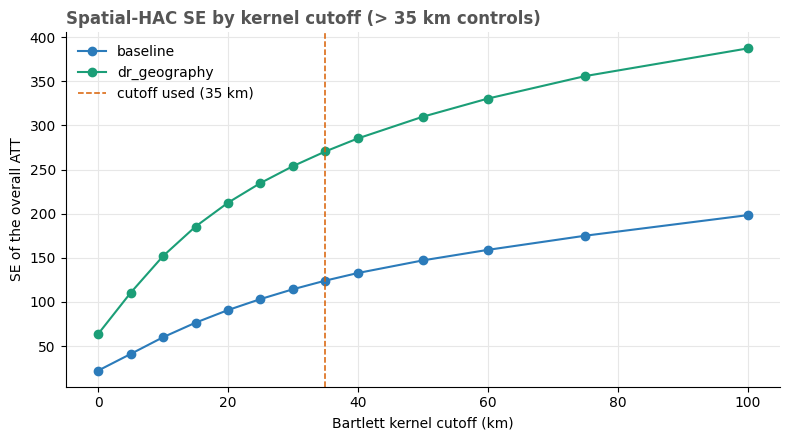

[26s]


In [13]:
t0 = time.time()
CUTOFFS_KM = [5, 10, 15, 20, 25, 30, 35, 40, 50, 60, 75, 100]
cut_rows = [{'estimator': name, 'cutoff_km': 0, 'se': float(np.sqrt(np.sum(psi_store[name] ** 2)))} for name in ['baseline', 'dr_geography']]
for c in CUTOFFS_KM:
    lat_c = lattice if c == HAC_CUTOFF_KM else ConleyLattice(xy[:, 0], xy[:, 1], cutoff_km=float(c))
    for name in ['baseline', 'dr_geography']:
        cut_rows.append({'estimator': name, 'cutoff_km': c, 'se': lat_c.se(psi_store[name])})
    if lat_c is not lattice:
        del lat_c
hac_cutoff = pd.DataFrame(cut_rows)
hac_cutoff['se_relative_to_35km'] = hac_cutoff['se'] / hac_cutoff['estimator'].map(hac_cutoff[hac_cutoff['cutoff_km'] == HAC_CUTOFF_KM].set_index('estimator')['se'])
hac_cutoff.to_csv(TABLE_DIR / f'13_hac_cutoff_sensitivity_{RUN_TAG}.csv', index=False)
display(hac_cutoff.pivot(index='cutoff_km', columns='estimator', values='se').round(1))
fig, ax = plt.subplots(figsize=(8, 4.5))
for name, col in [('baseline', '#2b7bba'), ('dr_geography', '#1b9e77')]:
    d = hac_cutoff[hac_cutoff['estimator'] == name]
    ax.plot(d['cutoff_km'], d['se'], marker='o', color=col, label=name)
ax.axvline(HAC_CUTOFF_KM, color='#d95f02', linestyle='--', linewidth=1.1, label=f'cutoff used ({HAC_CUTOFF_KM:g} km)')
ax.set_xlabel('Bartlett kernel cutoff (km)'); ax.set_ylabel('SE of the overall ATT')
ax.set_title('Spatial-HAC SE by kernel cutoff (> 35 km controls)', loc='left', color='#555555', fontsize=12, weight='bold')
ax.grid(True, color='#e7e7e7'); ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG_DIR / f'13_hac_cutoff_sensitivity_{RUN_TAG}.png', dpi=220, bbox_inches='tight'); plt.show()
print(f'[{time.time() - t0:.0f}s]')
shutil.rmtree(R_WORK_DIR, ignore_errors=True)

### Reading the results

* **Part A.** If `reg`, `ipw` and the trimmed DR agree with the default DR, the near-zero covariate-adjusted estimate is not a propensity-score artefact. `ipw` alone is the most sensitive to poor overlap; check it against the overlap table (controls with high scores, effective sample size).
* **Part B.** A few areas or blocks with a large share of the HAC variance, or a large pull on the point estimate, are the "outliers". If dropping them or winsorising changes the ATT a lot, the estimate rests on them; if the SE stays large, the imprecision is broad-based spatial correlation rather than a few outliers.
* **Part C.** A gradient that flattens beyond 35 km supports the main buffer; one that keeps moving (especially in the DR rows) means the comparison depends on how far from PAs the controls are, which is a selection/regional-trend issue no buffer resolves; all never-treated cells pool every band. An HAC SE that is still rising at 35 km calls for a wider cutoff in notebook 12. If the 10-20 km and > 35 km estimates agree up to 2016 but split after, the band differences come from the post-2016 surge in the frontier arc around parks, a regional trend rather than leakage.